---
title: "Лабораторна робота 4. Моделювання та дослідження динамічних процесів у складних мережах"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Лабораторна робота продовжує накопичувальний дослідницький артефакт курсу:

$$
\text{Model Specification v0.1}
\rightarrow
\text{Dynamic Model Specification v0.2} \\
\rightarrow
\text{Network Model Specification v0.3}
\rightarrow
\text{Network Dynamics Specification v0.4}.
$$

У ЛР3 ми відповіли на питання *«як формалізувати структуру взаємодій?»*. У ЛР4 головне питання інше:

> *Як структура мережі взаємодіє з локальним правилом процесу та формує макроскопічну динаміку?*

ЛР4 спирається на матеріал Лекції 4. Cascades, threshold processes, synchronization, robustness і resilience систематично продовжимо в Лекції 5.
:::

# Мета роботи

Набути практичної здатності задавати динамічний процес на складній мережі, відокремлювати topology від process rule, проводити відтворюваний ансамблевий обчислювальний експеримент і формулювати обмежені висновки щодо зв'язку *structure -- dynamics*.

# Завдання роботи

1. Побудувати контрольовані мережі різної topology.
2. Зафіксувати structural profile кожної мережі.
3. Формально задати node state, transition rule, parameters та initial condition.
4. Реалізувати SI-подібний stochastic spreading process.
5. Перевірити коректність реалізації через structural і dynamic sanity checks.
6. Показати, чому одна stochastic realization недостатня.
7. Побудувати ensemble trajectories.
8. Визначити macroscopic quantities of interest.
9. Провести контрольований topology experiment.
10. Перевірити чутливість висновку до initial condition.
11. Перенести схему на власний дисертаційний об'єкт.
12. Сформувати *Network Dynamics Specification v0.4*.

# Теоретичний мінімум

Мережева модель задає структуру:

$$
G=(V,E),
$$

але для динамічної моделі цього недостатньо. Потрібні states

$$
x_i(t)
$$

та transition rule:

$$
x_i(t+1)
=
F_i
\left(
x_i(t),
\{x_j(t):j\in\mathcal{N}_i\},
\theta
\right).
$$

У векторній формі:

$$
\mathbf{x}(t+1)
=
\mathbf{F}
\left(
\mathbf{x}(t),
A,
\Theta
\right).
$$

Тобто adjacency matrix $A$ входить безпосередньо до механізму еволюції [@newman2018; @barabasi2016].

## Логіка лабораторної роботи

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 G("Topology<br/>G=(V,E)") --> X("Node states<br/>x_i(t)")
 X --> R("Transition<br/>rule")
 R --> P("Parameters +<br/>initial condition")
 P --> E("Ensemble<br/>simulation")
 E --> Q("Dynamic<br/>QoI")
 Q --> I("Structure--dynamics<br/>inference")
```

# Частина I. Навчальний кейс

Продовжимо кейс поширення інформаційного стану в онлайн-спільноті.

Тепер ми навмисно працюємо не з одним empirical graph, а з кількома контрольованими topology. Це дозволяє відокремити питання

$$
\text{що робить процес?}
$$

від питання

$$
\text{що змінює структура?}
$$

Research Question:

> *Як topology мережі впливає на швидкість і варіабельність поширення за однакового локального правила?*

# 1. Імпорт бібліотек і параметри відтворюваності

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

BASE_SEED = 42
N = 100
BETA = 0.20
STEPS = 25
RUNS = 200

# 2. Три контрольовані topology

Побудуємо:

- випадкову мережу Erdős--Rényi (ER);
- мережу малого світу Watts--Strogatz (WS);
- мережу Barabási--Albert (BA).

Мережі мають однакове $N$ і близький mean degree. Ми не стверджуємо, що вони є точними моделями конкретної онлайн-спільноти. Тут вони виконують роль *controlled structural conditions* [@newman2018; @barabasi2016].

In [2]:
G_er = nx.erdos_renyi_graph(
    n=N,
    p=0.06,
    seed=BASE_SEED
)

G_ws = nx.watts_strogatz_graph(
    n=N,
    k=6,
    p=0.08,
    seed=BASE_SEED
)

G_ba = nx.barabasi_albert_graph(
    n=N,
    m=3,
    seed=BASE_SEED
)

graphs = {
    "ER": G_er,
    "WS": G_ws,
    "BA": G_ba
}

for name, G in graphs.items():
    print(
        name,
        "N =", G.number_of_nodes(),
        "M =", G.number_of_edges()
    )

ER N = 100 M = 269
WS N = 100 M = 300
BA N = 100 M = 291


# 3. Structural sanity checks

Перед запуском process experiment потрібно переконатися, що порівнюємо саме ті structures, які вважаємо побудованими.

Для simple undirected graph перевіряємо:

$$
A=A^T,
\qquad
a_{ii}=0,
\qquad
\sum_i k_i=2|E|.
$$

In [3]:
def structural_sanity_checks(G):
    nodes = list(G.nodes())
    A = nx.to_numpy_array(
        G,
        nodelist=nodes,
        dtype=int
    )

    return {
        "simple_graph": not G.is_multigraph(),
        "undirected": not G.is_directed(),
        "symmetric_A": np.array_equal(A, A.T),
        "zero_diagonal": np.all(np.diag(A) == 0),
        "degree_sum_equals_2E":
            sum(dict(G.degree()).values())
            == 2 * G.number_of_edges()
    }

for name, G in graphs.items():
    print(name, structural_sanity_checks(G))

ER {'simple_graph': True, 'undirected': True, 'symmetric_A': True, 'zero_diagonal': np.True_, 'degree_sum_equals_2E': True}
WS {'simple_graph': True, 'undirected': True, 'symmetric_A': True, 'zero_diagonal': np.True_, 'degree_sum_equals_2E': True}
BA {'simple_graph': True, 'undirected': True, 'symmetric_A': True, 'zero_diagonal': np.True_, 'degree_sum_equals_2E': True}


# 4. Structural profile

Для контрольованого експерименту недостатньо написати «ER», «WS» або «BA». Потрібно зафіксувати фактично отримані properties.

In [4]:
def structural_profile(G):
    degree = np.array(
        [d for _, d in G.degree()]
    )

    if nx.is_connected(G):
        H = G
        connected = True
    else:
        gcc = max(
            nx.connected_components(G),
            key=len
        )
        H = G.subgraph(gcc)
        connected = False

    return {
        "N": G.number_of_nodes(),
        "M": G.number_of_edges(),
        "density": nx.density(G),
        "mean_degree": degree.mean(),
        "degree_std": degree.std(),
        "average_clustering":
            nx.average_clustering(G),
        "connected": connected,
        "path_length_GCC":
            nx.average_shortest_path_length(H)
    }

profile = pd.DataFrame({
    name: structural_profile(G)
    for name, G in graphs.items()
}).T

profile.round(3)

,N,M,density,mean_degree,degree_std,average_clustering,connected,path_length_GCC
ER,100,269,0.054343,5.38,2.129695,0.053666,True,2.876768
WS,100,300,0.060606,6.0,0.632456,0.465,True,3.655556
BA,100,291,0.058788,5.82,5.505234,0.187024,True,2.515152


## Завдання 4.1

Для кожної topology сформулюйте короткий structural profile. Обов'язково порівняйте:

- $\langle k\rangle$;
- $\sigma_k$;
- clustering;
- average path length.

Поясніть, чому близький mean degree не робить мережі структурно еквівалентними.

# 5. Process specification

Визначимо binary node state:

$$
x_i(t)\in\{0,1\},
$$

де:

- $0$ -- вузол ще не активований;
- $1$ -- вузол активований.

Якщо

$$
m_i(t)
=
\sum_j a_{ij}x_j(t)
$$

-- кількість active neighbors, то

$$
P(x_i(t+1)=1\mid x_i(t)=0)
=
1-(1-\beta)^{m_i(t)}.
$$

Активований вузол залишається активованим.

::: callout-important
## Важливо

У цьому експерименті $\beta$ -- параметр *process model*, а $A$ -- параметр *structural condition*. Їх не можна змішувати в одному поясненні.
:::

# 6. Макроскопічна величина інтересу

Основна trajectory:

$$
\rho(t)
=
\frac{1}{N}
\sum_{i=1}^{N}x_i(t).
$$

Вона переводить node-level states у macro-level observable:

$$
A
\rightarrow
\{x_i(t)\}
\rightarrow
\rho(t).
$$

# 7. Реалізація одного stochastic run

In [5]:
def simulate_si(
    G,
    beta=BETA,
    steps=STEPS,
    initial_node=None,
    seed=BASE_SEED
):
    rng = np.random.default_rng(seed)
    nodes = list(G.nodes())

    state = {
        node: 0
        for node in nodes
    }

    if initial_node is None:
        initial_node = nodes[0]

    if initial_node not in state:
        raise ValueError(
            "initial_node відсутній у графі"
        )

    state[initial_node] = 1

    prevalence = [
        sum(state.values()) / len(nodes)
    ]

    for _ in range(steps):
        new_state = state.copy()

        for node in nodes:
            if state[node] == 1:
                continue

            m_i = sum(
                state[nbr]
                for nbr in G.neighbors(node)
            )

            p_activate = (
                1 - (1 - beta) ** m_i
            )

            if rng.random() < p_activate:
                new_state[node] = 1

        state = new_state

        prevalence.append(
            sum(state.values()) / len(nodes)
        )

    return np.asarray(prevalence)

# 8. Dynamic sanity checks

Для SI-подібної моделі маємо інваріанти:

$$
0\le\rho(t)\le1,
$$

$$
\rho(t+1)\ge\rho(t),
$$

оскільки recovery mechanism відсутній.

За

$$
\beta=0
$$

поширення не повинно відбуватися.

Ці checks випливають із моделі, а не з Python implementation.

In [6]:
def dynamic_sanity_checks(G):
    initial_node = list(G.nodes())[0]

    trajectory = simulate_si(
        G,
        beta=BETA,
        steps=STEPS,
        initial_node=initial_node,
        seed=BASE_SEED
    )

    zero_beta = simulate_si(
        G,
        beta=0.0,
        steps=STEPS,
        initial_node=initial_node,
        seed=BASE_SEED
    )

    return {
        "within_0_1":
            np.all(
                (trajectory >= 0)
                & (trajectory <= 1)
            ),
        "nondecreasing":
            np.all(
                np.diff(trajectory) >= 0
            ),
        "beta_0_no_spread":
            np.allclose(
                zero_beta,
                zero_beta[0]
            )
    }

for name, G in graphs.items():
    print(name, dynamic_sanity_checks(G))

ER {'within_0_1': np.True_, 'nondecreasing': np.True_, 'beta_0_no_spread': True}
WS {'within_0_1': np.True_, 'nondecreasing': np.True_, 'beta_0_no_spread': True}
BA {'within_0_1': np.True_, 'nondecreasing': np.True_, 'beta_0_no_spread': True}


# 9. Одна реалізація

Спочатку навмисно виконаємо лише один run.

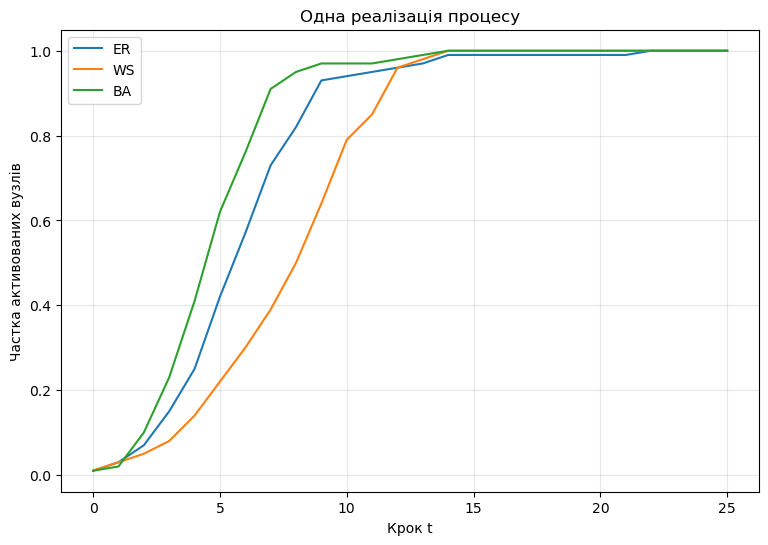

In [7]:
def median_degree_node(G):
    degree = dict(G.degree())
    median_k = np.median(
        list(degree.values())
    )

    return min(
        degree,
        key=lambda node:
            abs(degree[node] - median_k)
    )

initial_nodes = {
    name: median_degree_node(G)
    for name, G in graphs.items()
}

single_runs = {
    name: simulate_si(
        G,
        beta=BETA,
        steps=STEPS,
        initial_node=initial_nodes[name],
        seed=BASE_SEED
    )
    for name, G in graphs.items()
}

t = np.arange(STEPS + 1)

plt.figure(figsize=(9, 6))

for name, trajectory in single_runs.items():
    plt.plot(
        t,
        trajectory,
        label=name
    )

plt.xlabel("Крок t")
plt.ylabel("Частка активованих вузлів")
plt.title("Одна реалізація процесу")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 9.1

Спробуйте сформулювати висновок за одним рисунком, а потім поясніть, чому він методологічно слабкий.

Підказка:

$$
\text{single stochastic realization}
\neq
\text{typical system behavior}.
$$

# 10. Повторимо одну topology з різними seed

Якщо process stochastic, зміна `seed` не змінює математичну модель, але змінює realization.

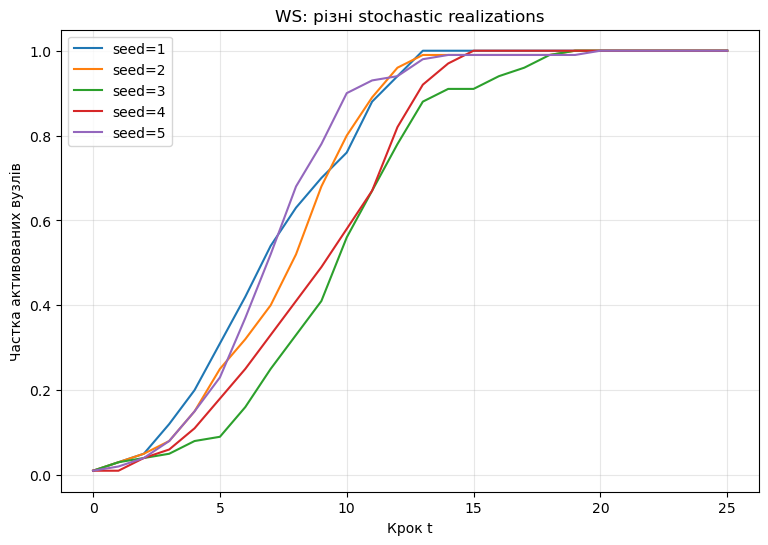

In [8]:
plt.figure(figsize=(9, 6))

for seed in [1, 2, 3, 4, 5]:
    trajectory = simulate_si(
        G_ws,
        beta=BETA,
        steps=STEPS,
        initial_node=initial_nodes["WS"],
        seed=seed
    )

    plt.plot(
        t,
        trajectory,
        label=f"seed={seed}"
    )

plt.xlabel("Крок t")
plt.ylabel("Частка активованих вузлів")
plt.title("WS: різні stochastic realizations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 11. Ансамбль реалізацій (ensemble)

Для кожної topology будуємо

$$
\{\rho^{(r)}(t)\}_{r=1}^{R}.
$$

У навчальному експерименті використовуємо

$$
R=200.
$$

In [9]:
def simulate_ensemble(
    G,
    beta=BETA,
    steps=STEPS,
    runs=RUNS,
    initial_node=None
):
    trajectories = []

    for seed in range(runs):
        trajectories.append(
            simulate_si(
                G,
                beta=beta,
                steps=steps,
                initial_node=initial_node,
                seed=seed
            )
        )

    X = np.vstack(trajectories)

    return {
        "raw": X,
        "mean": X.mean(axis=0),
        "median": np.median(X, axis=0),
        "q05": np.quantile(X, 0.05, axis=0),
        "q95": np.quantile(X, 0.95, axis=0)
    }

ensemble = {
    name: simulate_ensemble(
        G,
        initial_node=initial_nodes[name]
    )
    for name, G in graphs.items()
}

# 12. Mean trajectory та empirical band

Побудуємо mean trajectory та empirical 5--95% band.

::: callout-warning
## Застереження

Смуга між empirical quantiles 5% і 95% не є автоматично confidence interval і не є повним uncertainty quantification. Вона лише описує variability ансамблю за зафіксованої model specification.
:::

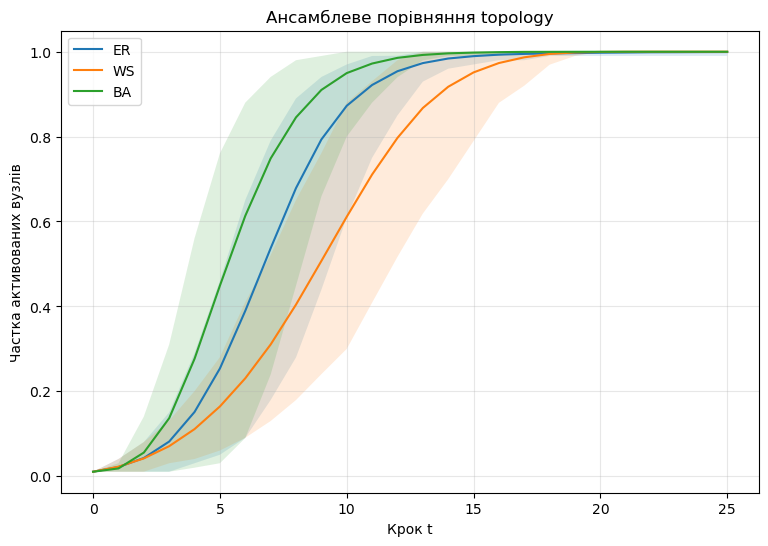

In [10]:
plt.figure(figsize=(9, 6))

for name, result in ensemble.items():
    plt.plot(
        t,
        result["mean"],
        label=name
    )

    plt.fill_between(
        t,
        result["q05"],
        result["q95"],
        alpha=0.15
    )

plt.xlabel("Крок t")
plt.ylabel("Частка активованих вузлів")
plt.title(
    "Ансамблеве порівняння topology"
)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 13. Dynamic quantities of interest

Однієї curve недостатньо для компактного comparison. Визначимо:

1. *time to 50% activation*
$$
T_{50}
=
\min\{t:\rho(t)\ge0.5\};
$$

2. *time to 90% activation*
$$
T_{90}
=
\min\{t:\rho(t)\ge0.9\};
$$

3. final activation
$$
\rho(T).
$$

Якщо threshold не досягнуто за horizon $T$, відповідний час вважаємо censored / not reached.

In [11]:
def first_passage_time(
    trajectory,
    threshold
):
    idx = np.where(
        trajectory >= threshold
    )[0]

    if len(idx) == 0:
        return np.nan

    return int(idx[0])

records = []

for name, result in ensemble.items():
    X = result["raw"]

    for run_id, trajectory in enumerate(X):
        records.append({
            "topology": name,
            "run": run_id,
            "T50":
                first_passage_time(
                    trajectory, 0.50
                ),
            "T90":
                first_passage_time(
                    trajectory, 0.90
                ),
            "rho_final":
                trajectory[-1]
        })

qoi = pd.DataFrame(records)
qoi.head()

,topology,run,T50,T90,rho_final
0,ER,0,9,13,1.0
1,ER,1,7,11,1.0
2,ER,2,6,9,1.0
3,ER,3,10,14,1.0
4,ER,4,9,12,1.0


In [12]:
qoi_summary = qoi.groupby(
    "topology"
).agg(
    T50_median=("T50", "median"),
    T50_mean=("T50", "mean"),
    T90_median=("T90", "median"),
    T90_mean=("T90", "mean"),
    rho_final_mean=("rho_final", "mean"),
    rho_final_std=("rho_final", "std")
)

qoi_summary.round(3)

,T50_median,T50_mean,T90_median,T90_mean,rho_final_mean,rho_final_std
topology,,,,,,
BA,6.0,5.90,8.0,8.590,1.000,0.000
ER,7.0,7.32,10.0,10.355,0.999,0.003
WS,10.0,9.55,13.0,13.475,1.000,0.000


## Завдання 13.1

Порівняйте topology не лише за mean curves, а й за $T_{50}$, $T_{90}$ та $\rho(T)$.

Для кожного висновку вкажіть:

- *що саме* порівнюється;
- *за яких параметрів*;
- *за якої initial-condition policy*;
- чи є висновок про structure, process або їх interaction.

# 14. Не плутаємо topology label із механізмом

Якщо BA у цьому experiment має менший $T_{50}$, не можна одразу стверджувати:

> «scale-free networks завжди прискорюють spreading».

Ми спостерігаємо результат для конкретного набору:

$$
(G,\beta,x(0),T,\text{source-selection rule}).
$$

Тому наукове твердження має бути bounded by model specification.

# 15. Initial condition як фактор експерименту

У spreading model source node може суттєво змінювати outcome.

Порівняємо для однієї topology:

- low-degree source;
- median-degree source;
- high-degree source.

In [13]:
def source_nodes_by_degree(G):
    degree = dict(G.degree())

    low = min(
        degree,
        key=degree.get
    )

    high = max(
        degree,
        key=degree.get
    )

    median = median_degree_node(G)

    return {
        "low_degree": low,
        "median_degree": median,
        "high_degree": high
    }

ba_sources = source_nodes_by_degree(G_ba)

pd.DataFrame({
    "node": ba_sources,
    "degree": {
        label: G_ba.degree(node)
        for label, node
        in ba_sources.items()
    }
})

,node,degree
low_degree,2,3
median_degree,11,4
high_degree,4,30


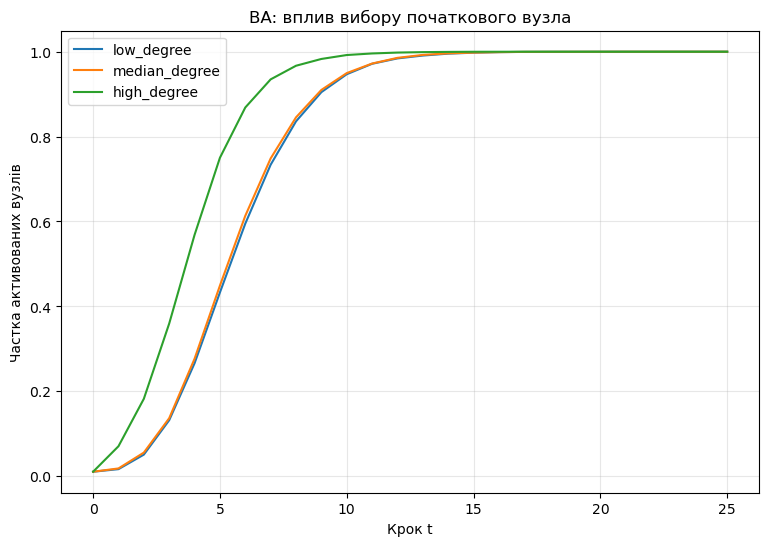

In [14]:
source_results = {
    label: simulate_ensemble(
        G_ba,
        initial_node=node
    )
    for label, node
    in ba_sources.items()
}

plt.figure(figsize=(9, 6))

for label, result in source_results.items():
    plt.plot(
        t,
        result["mean"],
        label=label
    )

plt.xlabel("Крок t")
plt.ylabel("Частка активованих вузлів")
plt.title(
    "BA: вплив вибору початкового вузла"
)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 15.1

Поясніть:

1. чи змінилася mean dynamics;
2. чи достатньо degree для пояснення зміни;
3. чому source-selection rule має бути частиною experiment specification.

Ключова логіка:

$$
\text{topology effect}
\neq
\text{source effect}.
$$

# 16. Мінімальний факторний погляд

Навіть у простому network experiment маємо щонайменше:

$$
\text{Outcome}
=
f(
\text{Topology},
\beta,
\text{Initial Condition},
\text{Stochastic Realization}
).
$$

Отже, порівняння topology коректне лише тоді, коли інші фактори контрольовані або явно варіюються за design.

# 17. Parameter sweep для $\beta$

Перевіримо, чи зберігається qualitative topology effect за кількох значень process parameter:

$$
\beta\in\{0.10,0.20,0.30\}.
$$

In [16]:
beta_values = [0.10, 0.20, 0.30]

beta_records = []

for beta in beta_values:
    for name, G in graphs.items():

        result = simulate_ensemble(
            G,
            beta=beta,
            initial_node=initial_nodes[name]
        )

        for trajectory in result["raw"]:
            beta_records.append({
                "beta": beta,
                "topology": name,
                "T50":
                    first_passage_time(
                        trajectory, 0.50
                    ),
                "rho_final":
                    trajectory[-1]
            })

beta_qoi = pd.DataFrame(beta_records)

beta_qoi.groupby(
    ["beta", "topology"]
).agg(
    T50_median=("T50", "median"),
    rho_final_mean=("rho_final", "mean")
).round(3)

T50_median  rho_final_mean
beta topology                            
0.1  BA              10.0           0.994
     ER              13.0           0.970
     WS              16.5           0.907
0.2  BA               6.0           1.000
     ER               7.0           0.999
     WS              10.0           1.000
0.3  BA               4.0           1.000
     ER               5.0           1.000
     WS               7.0           1.000

## Завдання 17.1

Визначте:

- які conclusions зберігаються для всіх трьох $\beta$;
- які conclusions змінюються;
- чи можна говорити про topology effect незалежно від process parameter.

# 18. Критичний аудит навчального кейсу

| Питання | Відповідь |
|---|---|
| Яке RQ досліджується? | |
| Що є node state? | |
| Яке transition rule? | |
| Що означає $\beta$? | |
| Що є initial condition? | |
| Як вибирається source node? | |
| Яка topology варіюється? | |
| Які factors контролюються? | |
| Що є stochastic realization? | |
| Навіщо ensemble? | |
| Які QoI використовуються? | |
| Який simulation horizon? | |
| Який висновок стійкий до $\beta$? | |
| Який висновок залежить від source? | |
| Що можна стверджувати про model? | |
| Чого не можна переносити на real system? | |

::: callout-tip
## Методологічний результат

ЛР4 має завершуватися не фразою «BA поширює швидше», а ланцюжком:

$$
RQ
\rightarrow
\text{structural condition}
\rightarrow
\text{process specification}
\rightarrow
\text{experimental control}
\rightarrow
\text{ensemble}
\rightarrow
\text{QoI}
\rightarrow
\text{bounded inference}.
$$
:::

# Частина II. Перенесення на дисертаційне дослідження

# 19. Чи існує network dynamics у Вашій задачі?

Використовуйте цей блок лише якщо в дисертаційній системі є осмислені:

- interacting entities;
- network representation;
- node/edge states або events;
- process, що розгортається через network structure.

Якщо цього немає, не потрібно штучно створювати spreading model. Побудуйте власний process rule, який відповідає Вашому RQ.

# 20. Research Question

Сформулюйте RQ типу:

> *Як характеристика структури $S(G)$ впливає на динамічну величину $\mathcal{D}(G)$ за контрольованих process parameters?*

або еквівалентне питання, коректне для Вашої предметної області.

# 21. Process specification

Заповніть таблицю.

| Компонент | Специфікація |
|---|---|
| Node state $x_i(t)$ | |
| State space | |
| Local neighborhood $\mathcal{N}_i$ | |
| Transition / evolution rule | |
| Process parameters | |
| Initial condition | |
| Boundary conditions, якщо є | |
| Stochastic mechanism | |
| Simulation horizon | |
| Time-step semantics | |

# 22. Structural condition

Визначте, що саме варіюється:

- observed network vs alternative specification;
- original vs perturbed network;
- кілька empirical networks;
- empirical vs null model;
- synthetic topologies.

Зміна topology повинна мати наукове обґрунтування.

# 23. Dynamic sanity checks

Сформулюйте щонайменше три checks, які випливають із Вашої математичної моделі.

Приклади:

- state bounds;
- conservation law;
- monotonicity;
- limiting behavior;
- zero-parameter behavior;
- symmetry;
- known special case.

# 24. Ensemble protocol

Якщо модель stochastic, зафіксуйте:

| Елемент | Значення |
|---|---|
| Number of runs $R$ | |
| Seed policy | |
| Що залишається fixed | |
| Що змінюється між runs | |
| Які summaries обчислюються | |
| Які empirical intervals використовуються | |

# 25. Quantity of Interest

Визначте не менше двох dynamic QoI:

$$
\mathcal{D}_1(G),
\qquad
\mathcal{D}_2(G).
$$

Вони мають безпосередньо відповідати RQ, а не бути обраними лише тому, що їх легко обчислити.

# 26. Контрольований structure--dynamics experiment

Побудуйте таблицю experiment design.

| Factor | Levels / values | Role |
|---|---|---|
| Topology / structural condition | | |
| Process parameter 1 | | |
| Initial condition | | |
| Stochastic realization | | |
| QoI | | |

Чітко відокремте:

$$
\text{factor}
\neq
\text{response}.
$$

# 27. Перевірка альтернативного пояснення

Оберіть щонайменше один потенційний confounder:

- source node;
- mean degree;
- density;
- network size;
- parameter value;
- observation window.

Покажіть, як Ви його контролюєте або явно включаєте в design.

# 28. Network Dynamics Specification v0.4

| Компонент | Специфікація v0.4 |
|---|---|
| Research Question | |
| Network Model Specification v0.3 | |
| Node state | |
| State space | |
| Transition / evolution rule | |
| Process parameters | |
| Initial-condition policy | |
| Stochastic mechanism | |
| Simulation horizon | |
| Structural condition / factor | |
| Controlled factors | |
| Ensemble protocol | |
| Dynamic QoI | |
| Sanity checks | |
| Alternative explanation / confounder | |
| Main bounded conclusion | |
| Limitations | |
| Reproducibility metadata | |

$$
\text{Network Model Specification v0.3}
\rightarrow
\text{Network Dynamics Specification v0.4}.
$$

# 29. Підсумковий артефакт ЛР4

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Network Model<br/>Specification v0.3") --> B("Process<br/>specification")
 B --> C("Dynamic<br/>sanity checks")
 C --> D("Ensemble<br/>experiment")
 D --> E("Dynamic<br/>QoI")
 E --> F("Confounder<br/>audit")
 F --> G("Network Dynamics<br/>Specification v0.4")
```

# Контрольні питання

1. Чому network topology сама по собі не є dynamic model?
2. Які компоненти потрібно додати до $G=(V,E)$?
3. Як adjacency matrix входить до transition rule?
4. Що означає node state?
5. Як виводиться $1-(1-\beta)^{m_i}$?
6. Що означає $\rho(t)$?
7. Чому SI trajectory має бути nondecreasing?
8. Навіщо dynamic sanity checks?
9. Чому один stochastic run недостатній?
10. Що таке ensemble?
11. Чим empirical quantile band відрізняється від confidence interval?
12. Що таке $T_{50}$?
13. Що робити, якщо threshold не досягнуто?
14. Чому потрібно фіксувати initial-condition policy?
15. Як source node може спотворити topology comparison?
16. Чому близький mean degree не робить topology еквівалентними?
17. Що означає controlled structure--dynamics experiment?
18. Чому topology label не є causal explanation?
19. Навіщо виконувати parameter sweep?
20. Що таке bounded inference?
21. Які variables є factors, а які responses?
22. Що таке confounder у computational experiment?
23. Коли synthetic topology доречна?
24. Коли SI-подібна модель недоречна для дисертаційного кейсу?
25. Які елементи повинна містити Network Dynamics Specification v0.4?

# Вимоги до звіту

У `.ipynb` мають бути:

- Research Question;
- structural conditions;
- structural profile;
- process specification;
- mathematical transition rule;
- reproducible implementation;
- structural sanity checks;
- dynamic sanity checks;
- single-run demonstration;
- ensemble experiment;
- mean trajectories та empirical bands;
- щонайменше дві dynamic QoI;
- initial-condition experiment;
- parameter sweep;
- critical audit;
- перенесення на дисертаційний кейс;
- *Network Dynamics Specification v0.4*;
- висновки.

::: callout-important
## Критерій якості

Оцінюється не складність simulation code, а цілісність дослідницького ланцюжка:

$$
\text{RQ}
\rightarrow
\text{model}
\rightarrow
\text{controlled experiment}
\rightarrow
\text{QoI}
\rightarrow
\text{scientific inference}.
$$
:::

# Висновки

У висновках дайте відповіді:

1. Який process моделювався?
2. Які structural conditions порівнювалися?
3. Які dynamic QoI використано?
4. Які conclusions стійкі до stochastic variability?
5. Які conclusions залежать від initial condition?
6. Які conclusions залежать від process parameter?
7. Яке альтернативне пояснення було перевірено?
8. Що можна стверджувати лише про model experiment?
9. Що потребує empirical validation перед перенесенням на real system?

# Джерела та корисні ресурси

Використовується спільна накопичувальна база `mmss-references.bib`.

- [Network Science -- Albert-László Barabási](https://networksciencebook.com/)
- [NetworkX documentation](https://networkx.org/documentation/stable/)
- [NetworkX graph generators](https://networkx.org/documentation/stable/reference/generators.html)
- [NumPy random generator](https://numpy.org/doc/stable/reference/random/generator.html)
- [pandas documentation](https://pandas.pydata.org/docs/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References